In [30]:

import os, json
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

DATA = '/kaggle/input/datasets/vasavnair/procced-features/processed_features'
MODELS = '/kaggle/working/wake_word_data/models'
os.makedirs(MODELS, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'



In [31]:
def load(dataset,data):
  d = np.load(f'{data}/{dataset}.npz')
  return d['X'], d['y'], d['words']


Xtrain, ytrain, wtrain = load('train',DATA)
Xtest, ytest, wtest = load('test',DATA)
Xval, yval, wval = load('val',DATA)



In [32]:
def loadToModel(X,y,shuffle):
  #pair each spectrogram with its label
  dataset = TensorDataset(torch.tensor(X).unsqueeze(1),torch.tensor(y)) #gives an explicit channel axis (1, 40, 101)
  #feeds model in batches of 64
  return DataLoader(dataset,batch_size=64,shuffle=shuffle)

train_dataloader = loadToModel(Xtrain,ytrain,True) # training is random shuffled
test_dataloader = loadToModel(Xtest,ytest,False)
val_dataloader = loadToModel(Xval,yval,False)



In [33]:
class NeuralNet(nn.Module):
  def __init__(self, channel_widths=(32,64,64), num_classes=3):
    super().__init__()
    layers, channel_in = [], 1
    for i, c in enumerate(channel_widths):
      layers += [nn.Conv2d(channel_in,c,3, padding=1),nn.BatchNorm2d(c),nn.ReLU()]
      if i < len(channel_widths) -1:
        layers.append(nn.MaxPool2d(2))
      channel_in = c
    layers.append(nn.AdaptiveAvgPool2d(1))
    self.features = nn.Sequential(*layers)
    self.classifier = nn.Sequential(nn.Dropout(0.3),nn.Linear(channel_widths[-1],num_classes))
  
  def forward(self,x):
    return self.classifier(self.features(x).flatten(1))






In [34]:
from sklearn.metrics import confusion_matrix


#need function to evaluate models performance
#talk about messing with threshold settings
def evaluate(model, dataloader, loss_function,wake,threshold=.4):
  model.eval()
  predictions, ground_truth_labels = [], []
  #dont need gradients for evaluation
  with torch.no_grad():
    for x,y in dataloader:
      x,y = x.to(device), y.to(device)
      predictions.append(model(x))
      ground_truth_labels.append(y)

  predictions = torch.cat(predictions)
  ground_truth_labels = torch.cat(ground_truth_labels)
  loss = loss_function(predictions,ground_truth_labels).item()

  probabilities = torch.softmax(predictions,dim=1)
  wake_prob = probabilities[:,wake]
  actual_wake_probs = wake_prob[ground_truth_labels == wake]

  print(
    f"Wake probabilities: "
    f"min={actual_wake_probs.min().item():.3f}, "
    f"max={actual_wake_probs.max().item():.3f}, "
    f"mean={actual_wake_probs.mean().item():.3f}"
  )

  pred = wake_prob >= threshold
  #talk about why i added softmax and threshold

  is_wake_word = ground_truth_labels == wake
  accuracy = (pred == is_wake_word).float().mean().item()
  fnr = (~pred[is_wake_word]).float().mean().item()
  fpr = (pred[~is_wake_word]).float().mean().item()

  cm = confusion_matrix(is_wake_word.cpu().numpy(),pred.cpu().numpy(),labels=[False,True])
  
  return loss, accuracy, fnr, fpr, cm

      
def train(model, name, epochs=30, learning_rate = .0003,wake_word=2):
  
  #talk about how learning rate was originally .001 in report
  model.to(device)
  optimizer = torch.optim.Adam(model.parameters(),lr=learning_rate)
  #talk about adding the scheduler in report
  scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs)
  loss_function = nn.CrossEntropyLoss()
  best_loss = float('inf')

  #for saving history
  history = {'train_loss':[],'val_loss':[],'val_acc':[],'val_fnr':[],'val_fpr':[]}
  for epoch in range(epochs):
    model.train()
    running, n = 0, 0
    for x,y in train_dataloader:
      x,y = x.to(device), y.to(device)
      optimizer.zero_grad() #clears prev batch gradients
      loss = loss_function(model(x),y)
      loss.backward() #computes gradients
      optimizer.step() #updates weights
      
      running += loss.item()*len(y)
      n += len(y)
    train_loss = running/n
    history['train_loss'].append(train_loss)  
    val_loss, val_acc, val_fnr, val_fpr, cm = evaluate(model, val_dataloader, loss_function, wake_word)
    print(f'ep {epoch+1:2d} train_loss {train_loss:.3f} val loss {val_loss:.3f}  acc {val_acc:.3f}  FPR {val_fpr:.3f}  FNR {val_fnr:.3f}')
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['val_fnr'].append(val_fnr)
    history['val_fpr'].append(val_fpr)
    if epoch % 5 == 0:
      print(cm)
    scheduler.step()
    if val_loss < best_loss:
      best_loss = val_loss
      torch.save(model.state_dict(),f'{MODELS}/{name}.pt')
  return best_loss,history


In [35]:



#model = NeuralNet(channel_widths=(32,64,64))
#best_val_loss,run_history =train(model,'baseline')

PLOTS = '/kaggle/working/wake_word_data/plots'
os.makedirs(PLOTS,exist_ok=True)
RESULTS = '/kaggle/working/wake_word_data/results'
os.makedirs(RESULTS,exist_ok=True)

def run(name, widths, epochs=30):
  torch.manual_seed(0)
  model = NeuralNet(channel_widths=widths)
  num_params = sum(p.numel() for p in model.parameters())
  best_loss,run_history =train(model,name,epochs=epochs)
  run_history.update(best_val_lost=best_loss,best_epoch=int(np.argmin(run_history['val_loss']))+1,num_params=num_params)
  with open(f'{RESULTS}/{name}_history.json','w') as f:
    json.dump(run_history,f)
  return run_history


two_layer = run('two_layer',(32,64))






Wake probabilities: min=0.115, max=0.272, mean=0.193
ep  1 train_loss 0.799 val loss 0.631  acc 0.833  FPR 0.000  FNR 1.000
[[975   0]
 [195   0]]
Wake probabilities: min=0.090, max=0.414, mean=0.235
ep  2 train_loss 0.612 val loss 0.576  acc 0.834  FPR 0.000  FNR 0.995
Wake probabilities: min=0.066, max=0.395, mean=0.228
ep  3 train_loss 0.564 val loss 0.528  acc 0.833  FPR 0.000  FNR 1.000
Wake probabilities: min=0.061, max=0.508, mean=0.259
ep  4 train_loss 0.531 val loss 0.495  acc 0.841  FPR 0.005  FNR 0.928
Wake probabilities: min=0.050, max=0.600, mean=0.268
ep  5 train_loss 0.502 val loss 0.473  acc 0.844  FPR 0.010  FNR 0.887
Wake probabilities: min=0.050, max=0.570, mean=0.277
ep  6 train_loss 0.475 val loss 0.450  acc 0.847  FPR 0.011  FNR 0.862
[[964  11]
 [168  27]]
Wake probabilities: min=0.027, max=0.611, mean=0.241
ep  7 train_loss 0.458 val loss 0.441  acc 0.843  FPR 0.009  FNR 0.897
Wake probabilities: min=0.036, max=0.730, mean=0.315
ep  8 train_loss 0.447 val loss 0

In [36]:
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 16})

def plot_graphs(history,name):
  epoch = range(1,len(history['train_loss'])+1)
  plt.figure(figsize=(12,8))
  plt.plot(epoch,history['train_loss'],'b',label='Training loss')
  plt.plot(epoch,history['val_loss'],'r',label='Validation loss')
  plt.title(f'Training and validation loss {name}')
  plt.xlabel('Epochs')
  plt.ylabel('Loss')
  plt.legend()
  plt.savefig(f'{PLOTS}/{name}_loss.png',dpi=200,bbox_inches='tight')
  plt.show()


#plot_graphs(base,'baseline')

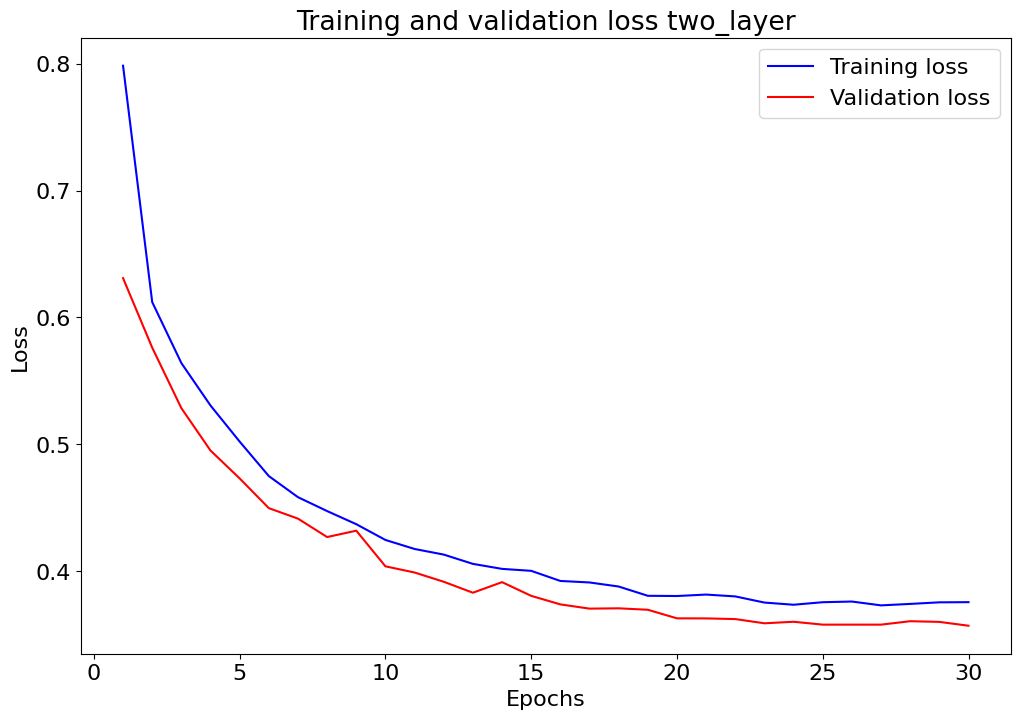

In [37]:
plot_graphs(two_layer,'two_layer')

Wake probabilities: min=0.160, max=0.451, mean=0.272
ep  1 train_loss 0.764 val loss 0.621  acc 0.835  FPR 0.002  FNR 0.979
[[973   2]
 [191   4]]
Wake probabilities: min=0.106, max=0.379, mean=0.258
ep  2 train_loss 0.579 val loss 0.528  acc 0.833  FPR 0.000  FNR 1.000
Wake probabilities: min=0.073, max=0.526, mean=0.297
ep  3 train_loss 0.506 val loss 0.493  acc 0.838  FPR 0.008  FNR 0.933
Wake probabilities: min=0.058, max=0.583, mean=0.345
ep  4 train_loss 0.461 val loss 0.464  acc 0.850  FPR 0.041  FNR 0.697
Wake probabilities: min=0.053, max=0.736, mean=0.387
ep  5 train_loss 0.424 val loss 0.431  acc 0.846  FPR 0.066  FNR 0.595
Wake probabilities: min=0.018, max=0.564, mean=0.265
ep  6 train_loss 0.394 val loss 0.408  acc 0.845  FPR 0.004  FNR 0.908
[[971   4]
 [177  18]]
Wake probabilities: min=0.022, max=0.703, mean=0.320
ep  7 train_loss 0.369 val loss 0.365  acc 0.867  FPR 0.015  FNR 0.723
Wake probabilities: min=0.047, max=0.870, mean=0.541
ep  8 train_loss 0.348 val loss 0

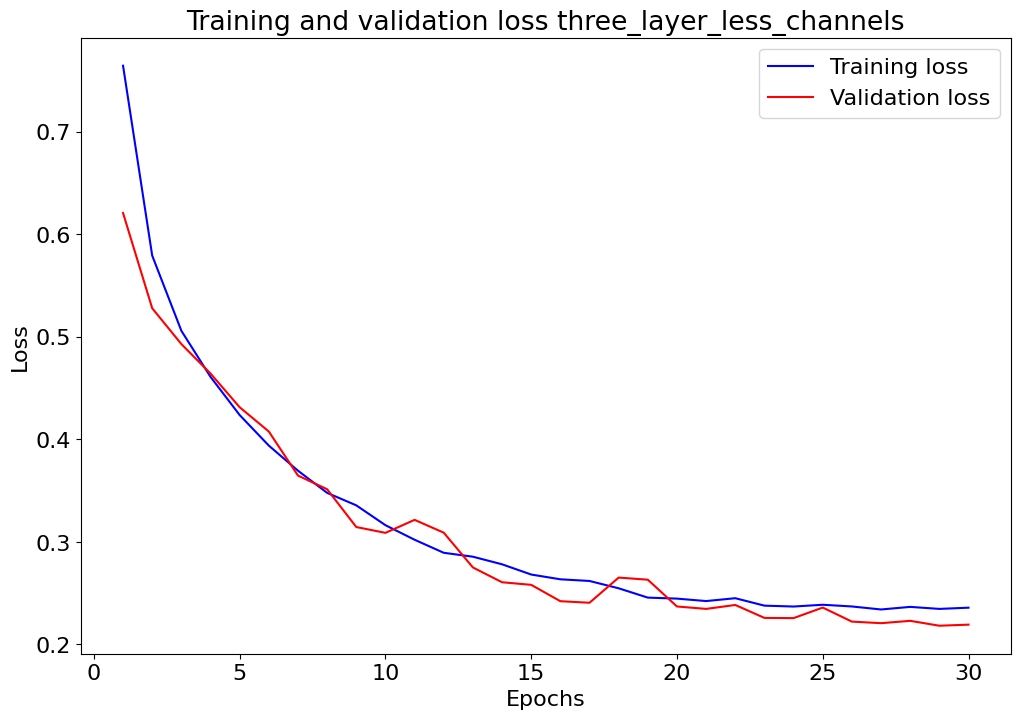

In [38]:
three_layer_less_channels = run('three_layer_less_channels',(16,32,32))
plot_graphs(three_layer_less_channels,'three_layer_less_channels')

Wake probabilities: min=0.143, max=0.296, mean=0.220
ep  1 train_loss 0.837 val loss 0.684  acc 0.833  FPR 0.000  FNR 1.000
[[975   0]
 [195   0]]
Wake probabilities: min=0.128, max=0.286, mean=0.205
ep  2 train_loss 0.665 val loss 0.618  acc 0.833  FPR 0.000  FNR 1.000
Wake probabilities: min=0.111, max=0.287, mean=0.195
ep  3 train_loss 0.614 val loss 0.580  acc 0.833  FPR 0.000  FNR 1.000
Wake probabilities: min=0.106, max=0.300, mean=0.207
ep  4 train_loss 0.586 val loss 0.554  acc 0.833  FPR 0.000  FNR 1.000
Wake probabilities: min=0.104, max=0.299, mean=0.208
ep  5 train_loss 0.564 val loss 0.536  acc 0.833  FPR 0.000  FNR 1.000
Wake probabilities: min=0.068, max=0.415, mean=0.213
ep  6 train_loss 0.543 val loss 0.515  acc 0.833  FPR 0.001  FNR 0.995
[[974   1]
 [194   1]]
Wake probabilities: min=0.074, max=0.446, mean=0.238
ep  7 train_loss 0.527 val loss 0.500  acc 0.835  FPR 0.003  FNR 0.974
Wake probabilities: min=0.068, max=0.415, mean=0.229
ep  8 train_loss 0.512 val loss 0

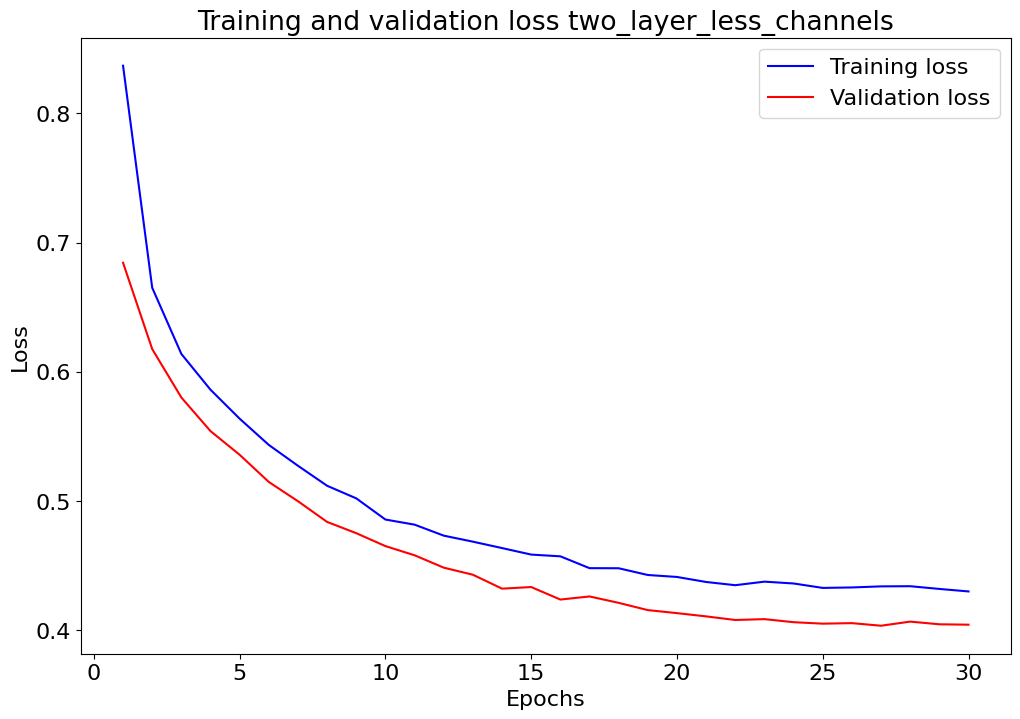

In [39]:
two_layer_less_channels = run('two_layer_less_channels',(16,32))
plot_graphs(two_layer_less_channels,'two_layer_less_channels')

Wake probabilities: min=0.122, max=0.560, mean=0.334
ep  1 train_loss 0.651 val loss 0.556  acc 0.844  FPR 0.023  FNR 0.821
[[953  22]
 [160  35]]
Wake probabilities: min=0.033, max=0.591, mean=0.276
ep  2 train_loss 0.470 val loss 0.443  acc 0.845  FPR 0.010  FNR 0.877
Wake probabilities: min=0.066, max=0.861, mean=0.543
ep  3 train_loss 0.403 val loss 0.389  acc 0.842  FPR 0.155  FNR 0.174
Wake probabilities: min=0.010, max=0.536, mean=0.205
ep  4 train_loss 0.345 val loss 0.401  acc 0.844  FPR 0.000  FNR 0.938
Wake probabilities: min=0.001, max=0.311, mean=0.077
ep  5 train_loss 0.313 val loss 0.633  acc 0.833  FPR 0.000  FNR 1.000
Wake probabilities: min=0.019, max=0.909, mean=0.485
ep  6 train_loss 0.291 val loss 0.275  acc 0.921  FPR 0.032  FNR 0.318
[[944  31]
 [ 62 133]]
Wake probabilities: min=0.024, max=0.935, mean=0.527
ep  7 train_loss 0.266 val loss 0.264  acc 0.918  FPR 0.041  FNR 0.287
Wake probabilities: min=0.021, max=0.975, mean=0.627
ep  8 train_loss 0.250 val loss 0

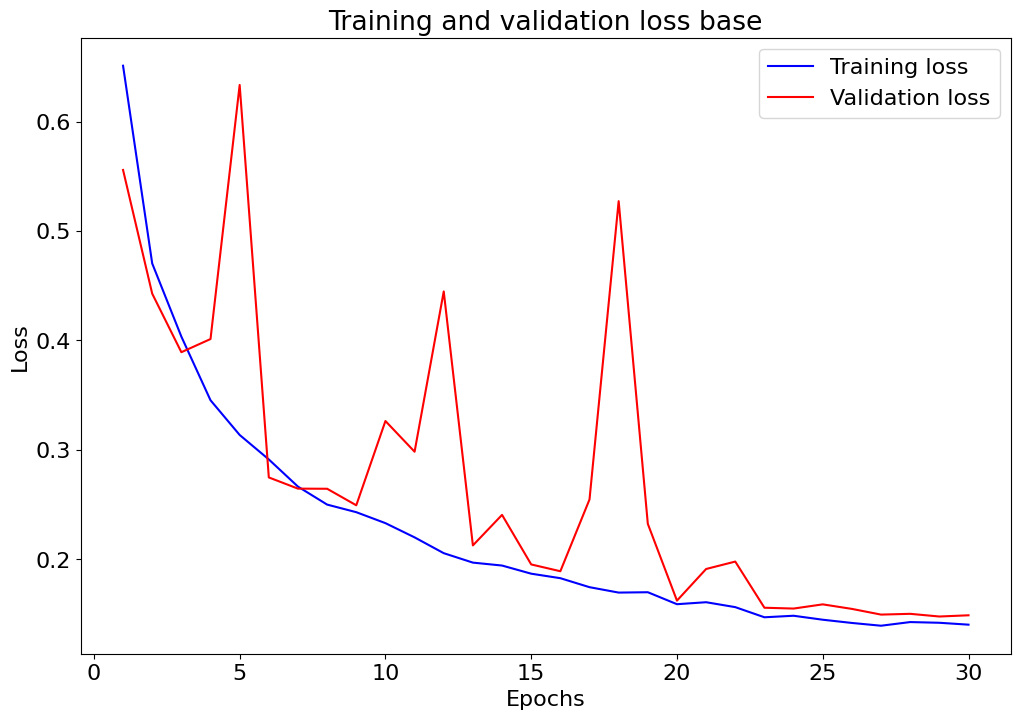

In [40]:
base = run('base',(32,64,64))
plot_graphs(base,'base')

In [41]:
!zip -r output_folder.zip /kaggle/working/wake_word_data

updating: kaggle/working/wake_word_data/ (stored 0%)
updating: kaggle/working/wake_word_data/plots/ (stored 0%)
updating: kaggle/working/wake_word_data/plots/three_layer_less_channels_loss.png (deflated 14%)
updating: kaggle/working/wake_word_data/plots/base_loss.png (deflated 13%)
updating: kaggle/working/wake_word_data/plots/two_layer_less_channels_loss.png (deflated 15%)
updating: kaggle/working/wake_word_data/plots/two_layer_loss.png (deflated 15%)
updating: kaggle/working/wake_word_data/results/ (stored 0%)
updating: kaggle/working/wake_word_data/results/two_layer_less_channels_history.json (deflated 63%)
updating: kaggle/working/wake_word_data/results/two_layer_history.json (deflated 60%)
updating: kaggle/working/wake_word_data/results/three_layer_less_channels_history.json (deflated 56%)
updating: kaggle/working/wake_word_data/results/base_history.json (deflated 56%)
updating: kaggle/working/wake_word_data/models/ (stored 0%)
  adding: kaggle/working/wake_word_data/models/two_la